# Can the forward model change the inferred cortical layer?

Given the same MEG signal and a known cortical location, does seeded MSP favor the
pial or the white surface? We simulate a dipole with known depth using the anatomy,
sensor layout and epoch timing of sub-104. We fit each simulated recording twice,
using the SPM single-shell forward and a one-compartment MNE boundary element
model (BEM). The pial and white hypotheses share the same vertex at each depth.

The BEM simulation asks what happens when that particular forward generated the
signal. We also simulate with the single-shell forward at the same vertex and SNR.
The location is deliberately selected to expose a possible disagreement. Its
frequency across repeated noise draws describes that location and SNR. In the
example below, a white-surface dipole in the left cuneus at 0 dB was classified
as pial by single shell and as white by BEM on three held-out noise draws.

With two forwards already prepared, the analysis itself is a pair of calls to laMEG.
Give each run a separate SPM copy of the **same sensor recording**, use the common
surfaces, and compare the pial and white entries of each returned evidence vector.

```python
evidence = {}
for name, operator, recording in (("single shell", shell, shell_recording),
                                  ("BEM", bem, bem_recording)):
    evidence[name], _ = model_comparison(
        fids, recording, prepared.surfaces, method="MSP", forward_operator=operator,
        invert_kwargs={"priors": [patch_vertex]},
    )
```

The following setup builds both forwards from the distributed data. Readers with
their own forward operators can jump to **Use free energy to compare pial and white**
for the fit settings and the signed layer contrast.

## Data and setup

Install laMEG from the repository with the forward-operator support, and run
`lameg-postinstall` to configure SPM. Extract the
[laMEG test data](https://osf.io/x4zd3/download) so that `test_data/`
contains `participants.tsv`, `sub-104/` and `fs/`. Run this tutorial from
the repository root or its `tutorials/` directory. For another data location,
set the environment variable `LAMEG_TEST_DATA` to the extracted `test_data`
directory.

The reference run used Python 3.7.16, MNE-Python 1.3.1 and DANC SPM standalone v0.1.2.
The run reads the FIF and SPM versions of the same CTF recording. It writes
derived meshes, gain matrices and simulated recordings into a temporary directory.
The output cells in the notebook show the results from a completed run.

In [1]:
from copy import copy
from pathlib import Path
from tempfile import TemporaryDirectory
import os
import shutil

import matplotlib.pyplot as plt
import mne
import nibabel as nib
import numpy as np
import spm_standalone
from mne.transforms import Transform, apply_trans
from scipy.io import savemat

from lameg.forward import ForwardOperator, prepare_mne_forward
from lameg.invert import coregister
from lameg.laminar import model_comparison
from lameg.surf import LayerSurfaceSet, _concatenate_surfaces, _remove_vertices
from lameg.util import get_fiducial_coords, load_meg_sensor_data

if os.environ.get("LAMEG_TEST_DATA"):
    data_root = Path(os.environ["LAMEG_TEST_DATA"]).expanduser().resolve()
else:
    data_root = next((parent / "test_data" for parent in (Path.cwd(), *Path.cwd().parents)
                      if (parent / "test_data" / "participants.tsv").is_file()), None)
if data_root is None or not (data_root / "participants.tsv").is_file():
    raise FileNotFoundError("Extract the laMEG test_data archive or set LAMEG_TEST_DATA.")
os.environ["SUBJECTS_DIR"] = str(data_root / "fs")

## Keep the same anatomical sites at both depths

The full cortex is unnecessary for this local question. Starting at the first pial
triangle, we include rings of adjacent faces until there are at least 350 vertices.
We crop the white mesh with the same indices. Complete triangles and the saved
signed dipole directions are needed for the later inversions. `full_ids` maps
indices on this initial patch back to the original downsampled cortical surface.

In [2]:
def copy_recording(source, directory):
    """Copy the SPM header and the binary recording it references together."""
    source, directory = Path(source), Path(directory)
    directory.mkdir(parents=True)
    for path in (source, source.with_suffix('.dat')):
        shutil.copy2(str(path), str(directory / path.name))
    return directory / source.name


def cortical_patch(surfaces, destination, first_face=0, minimum_vertices=350):
    """Extract the same connected neighbourhood at both depths and keep its anatomical IDs."""
    layers = surfaces.get_layer_names()
    meshes = [nib.load(surfaces.get_mesh_path(layer_name=name)) for name in layers]
    faces = meshes[0].get_arrays_from_intent('NIFTI_INTENT_TRIANGLE')[0].data
    np.testing.assert_array_equal(faces, meshes[1].get_arrays_from_intent('NIFTI_INTENT_TRIANGLE')[0].data)
    keep = np.zeros(len(meshes[0].darrays[0].data), dtype=bool)
    keep[faces[first_face]] = True
    # Grow by complete triangle rings; extracting isolated points would break cortical smoothing.
    while keep.sum() < minimum_vertices:
        previous_count = keep.sum()
        keep[faces[keep[faces].any(axis=1)]] = True
        if keep.sum() == previous_count:
            raise ValueError("The connected component is smaller than the requested patch.")
    # These laMEG mesh utilities carry the saved signed link directions through renumbering.
    # The first kept vertex is patch vertex zero, but may have any ID on the complete cortex.
    patch = copy(surfaces)
    destination.mkdir()
    patch.laminar_surf_dir = str(destination)
    patches = [_remove_vertices(mesh, np.flatnonzero(~keep)) for mesh in meshes]
    for layer, mesh in zip(layers, patches):
        nib.save(mesh, patch.get_mesh_path(layer_name=layer))
    nib.save(_concatenate_surfaces(patches), patch.get_mesh_path())
    return patch, np.flatnonzero(keep)

## Compute the two forward operators

Both solvers receive the same triangulated inner-skull surface warped to
sub-104's MRI. SPM uses the single-shell approximation of Nolte (2003). MNE uses a
one-compartment BEM with conductivity 0.3 S/m. This comparison therefore concerns
two implementations of the MEG forward calculation, each using one compartment.

SPM's coregistration uses native MRI and CTF head coordinates. MNE uses FreeSurfer
surface RAS and MNE head coordinates. The transforms below place the head surface,
dipoles and coils in their respective frames. We keep the signed current directions
and CTF reference compensation when constructing the two operators. The SPM data
carry measured pickup geometry. The MNE forward uses nominal CTF coils, which
laMEG checks against those measured coils.

In [3]:
def native_operator(source, directory, surfaces, fids, skull, spm):
    """Register a separate SPM recording copy and read its signed single-shell gain."""
    recording = copy_recording(source, directory)
    coregister(fids, str(recording), surfaces, forward_model_type='Single Shell',
               iskull_fname=str(skull), viz=False, spm_instance=spm)
    # Ask SPM to compute the gain and write its cache before importing signed columns.
    filename = str(recording).replace("'", "''")
    spm.spm_standalone('eval', "D=spm_eeg_load('%s'); spm_eeg_lgainmat(D);" % filename,
                       nargout=0)
    return recording, ForwardOperator.from_spm(
        str(recording), surfaces.get_mesh_path(), surfaces.get_layer_names(),
        allow_undefined_gain=True)


def subject_bem(surfaces, skull, info, mri_to_ctf_mm, directory):
    """Compute one-compartment MNE gains at the original patch vertices of each layer."""
    # The GIfTI files are in native MRI mm. MNE needs FreeSurfer surface RAS for the skull
    # and source space, and a transform from that frame to the acquisition's MNE head frame.
    mri = Path(surfaces.mri_file)
    tkr = nib.load(str(mri.with_name('orig.mgz'))).header.get_vox2ras_tkr()
    native_to_ras = tkr @ np.linalg.inv(nib.load(str(mri)).affine)
    mne_to_ctf = np.linalg.inv(info['ctf_head_t']['trans'])
    mne_to_ctf[:3, 3] *= 1000  # CTF and native transforms now both act on mm.
    ras_to_head = np.linalg.inv(mne_to_ctf) @ mri_to_ctf_mm @ np.linalg.inv(native_to_ras)
    ras_to_head[:3, 3] /= 1000  # MNE applies the MRI-to-head transform to points in metres.
    trans = Transform('mri', 'head', ras_to_head)

    # Each solver uses this exact triangulated inner skull from the participant's MRI.
    inner = nib.load(str(skull))
    points = inner.get_arrays_from_intent('NIFTI_INTENT_POINTSET')[0].data
    faces = inner.get_arrays_from_intent('NIFTI_INTENT_TRIANGLE')[0].data
    bem_dir = directory / surfaces.subj_id / 'bem'
    bem_dir.mkdir(parents=True)
    mne.write_surface(str(bem_dir / 'inner_skull.surf'), apply_trans(native_to_ras, points), faces)
    model = mne.make_bem_model(surfaces.subj_id, ico=None, conductivity=(0.3,), subjects_dir=directory)
    bem = mne.make_bem_solution(model)
    forwards = {}
    for layer in surfaces.get_layer_names():
        mesh = nib.load(surfaces.get_mesh_path(layer_name=layer))
        positions = apply_trans(native_to_ras, mesh.darrays[0].data) / 1000
        # Ask for three Cartesian gains per site. The initial normal is only needed by
        # the discrete source-space constructor. laMEG projects onto the saved link vector.
        src = mne.setup_volume_source_space(
            pos={'rr': positions, 'nn': np.tile([0., 0., 1.], (len(positions), 1))})
        forwards[layer] = mne.make_forward_solution(
            info, trans, src, bem, meg=True, eeg=False, mindist=0., ignore_ref=False)
    return forwards

## Match vertices and sensor rows

MNE can exclude a pial source outside the inner skull even when its white counterpart
is available. `prepare_mne_forward` returns meshes on which every retained vertex
exists at both depths. We compute the single-shell operator on those same meshes.

There are three distinct indices. The full-surface ID locates a point on the original
cortex. The patch ID is the MSP prior that the prepared surfaces accept. The compact
index selects a gain column after the BEM exclusions. We retain both mappings below.

In [4]:
def build_operators(data_root, work, spm, first_face=0, minimum_vertices=350):
    """Prepare both models on the same cortical vertices, sensors, head pose and skull."""
    data_root, work = Path(data_root).resolve(), Path(work).resolve()
    ses = data_root / 'sub-104' / 'meg' / 'ses-01'
    source = ses / 'spm' / 'spm-converted_autoreject-sub-104-ses-01-001-btn_trial-epo.mat'
    info = mne.io.read_info(str(ses / 'mne' / 'autoreject-sub-104-ses-01-001-btn_trial-epo.fif'))
    fids = get_fiducial_coords('sub-104', str(data_root / 'participants.tsv'))
    original = LayerSurfaceSet('sub-104', 2, subjects_dir=str(data_root / 'fs'))
    patch, full_ids = cortical_patch(original, work / 'patch', first_face, minimum_vertices)

    # SPM may write intermediate files near the MRI. Run in an independent working copy.
    # Keep the saved normalization (y_orig and seg8) so SPM can reuse the subject's fit.
    (work / 'mri').mkdir()
    for name in ('orig.nii', 'orig.mgz', 'y_orig.nii', 'orig_seg8.mat'):
        shutil.copy2(str(Path(original.mri_file).with_name(name)), str(work / 'mri' / name))
    patch.mri_file = str(work / 'mri' / 'orig.nii')
    # Pass the distributed inner skull as a separate read-only input. SPM may regenerate
    # default meshes inside the working MRI directory during each registration.
    skull = Path(original.mri_file).with_name('origiskull_2562.surf.gii')
    donor, native = native_operator(source, work / 'registration', patch, fids, skull, spm)
    forwards = subject_bem(patch, skull, info, native.mri_to_head_mm, work / 'bem')
    prepared = prepare_mne_forward(
        forwards, patch, work, reference=donor, info=info, ignore_ref=False,
        allow_nominal_ctf_coils=True)

    # Restrict the single-shell model to exactly the mesh used by BEM. Both operators now
    # use the order of prepared.support.original_vertices within each anatomical layer.
    _, shell = native_operator(source, work / 'single-shell', prepared.surfaces, fids, skull, spm)
    assert shell.layer_names == prepared.operator.layer_names == ('pial', 'white')
    assert shell.channel_names == prepared.operator.channel_names
    assert shell.channel_units == prepared.operator.channel_units
    np.testing.assert_array_equal(shell.requested_mri_mm, prepared.operator.requested_mri_mm)
    np.testing.assert_allclose(shell.orientations_head, prepared.operator.orientations_head, atol=1e-5)
    return source, fids, prepared, shell, full_ids, skull

In [5]:
# Use a fresh working directory for each run so SPM headers and caches are isolated.
workspace = TemporaryDirectory(prefix="lameg-shell-bem-")
work = Path(workspace.name)
mne.set_log_level("WARNING")
spm_standalone.initialize_runtime(["-nojvm"])
spm = spm_standalone.initialize()
source, fids, prepared, shell, full_ids, skull = build_operators(data_root, work, spm)
bem = prepared.operator
patch_ids = prepared.support.original_vertices
anatomical_ids = full_ids[patch_ids]
layer_names = tuple(bem.layer_names)
# Time is returned in milliseconds. Only the acquisition timing is used.
_, time_ms, channel_names = load_meg_sensor_data(str(source))
del _
assert tuple(channel_names) == shell.channel_names == bem.channel_names
print(f"Tutorial geometry: {len(channel_names)} sensors; {len(full_ids)} patch vertices; "
      f"{len(patch_ids)} retained at both depths.")

Tutorial geometry: 274 sensors; 370 patch vertices; 337 retained at both depths.


## Screen the two possible source depths

A point source has one signed sensor topography per layer. Squared cosine
similarity gives the fraction of a noiseless topography explained after fitting
its scalar amplitude. For each shared vertex we generate the topography under BEM
at each possible depth. We rank locations by the smaller of two differences:
the BEM's preference for the correct depth and the single shell's preference for the
other depth. Positive values mean that the two geometric comparisons disagree.

This screen uses the gains alone and is cheap to repeat across the patch. The MSP
fits below use the time series and variational free energy to decide which cortical
layer wins.

In [6]:
def rank_candidates(bem_gain, shell_gain, layer_names=("pial", "white")):
    """Find sites where a matched BEM topography and the shell prefer opposite depths."""
    if (bem_gain.shape != shell_gain.shape or bem_gain.ndim != 2 or
            bem_gain.shape[1] % 2 or len(layer_names) != 2):
        raise ValueError("Need matched channel-by-source gains for two equal-sized layers.")
    n_sensors, n_sources = bem_gain.shape
    n_vertices = n_sources // 2
    # The two consecutive blocks use the same anatomical vertex order. A scalar
    # source amplitude, including its polarity, is a nuisance when fitting a layer.
    # Squared cosine is the fraction of a noiseless topography explained after
    # fitting that scalar by least squares. It is a screening score, not evidence.
    gains = np.stack((bem_gain, shell_gain)).reshape(2, n_sensors, 2, n_vertices)
    norms = np.linalg.norm(gains, axis=1)
    defined = np.all(np.isfinite(norms) & (norms > 0), axis=(0, 1))
    unit = gains / np.where(norms > 0, norms, 1)[:, None]
    scores = []
    for layer in range(2):
        observed = unit[0, :, layer, :]
        # Fit each candidate layer from each solver to the SAME BEM-generated field.
        explained = np.einsum('sclv,cv->slv', unit, observed)**2
        bem_advantage = explained[0, layer] - explained[0, 1-layer]
        shell_error_advantage = explained[1, 1-layer] - explained[1, layer]
        margin = np.where(defined, np.minimum(bem_advantage, shell_error_advantage), -np.inf)
        scores.append((margin, bem_advantage, shell_error_advantage))
    return np.array(scores), unit

In [7]:
scores, unit_topographies = rank_candidates(bem.gain, shell.gain)
print("Tutorial geometry screen (positive margin / evaluated), by simulated depth")
for layer, label in enumerate(layer_names):
    margins = scores[layer, 0]
    print(f"{label:>6s}   {int((margins > 1e-12).sum()):3d} / {np.isfinite(margins).sum()}")

Tutorial geometry screen (positive margin / evaluated), by simulated depth
  pial    89 / 337
 white    38 / 337


## Simulate a known source in sub-104 sensor space

The recording supplies the channel names, positions and epoch timing. The sensor
samples for the inversion are simulated. We add independent Gaussian noise across
sensors and time to a 20 Hz dipole burst. The SNR is defined on the 100–200 ms
analysis window as 20 times the base-10 logarithm of signal RMS divided by noise
RMS over channels and time. Using each realized noise RMS makes that ratio exact.

For a given generator, vertex, SNR and seed, both inversions receive exactly the
same sensor samples. With the opposite generator, the same seed gives the same
standardized noise pattern scaled to the new signal RMS.

In [8]:
def simulate_evoked(time_ms, topography, snr_db, seed):
    """One point source plus Gaussian sensor noise in the sub-104 channel units (fT)."""
    time_ms = np.asarray(time_ms, dtype=float)
    topography = np.asarray(topography, dtype=float)
    # A 100-ms Hann envelope contains two cycles at 20 Hz. Only this window enters
    # the SNR calculation and the subsequent inversion.
    elapsed = (time_ms - 100.) / 1000.
    # Include the endpoints even when 100 ms is represented as 99.99999999999997.
    active = (time_ms >= 100. - 1e-7) & (time_ms <= 200. + 1e-7)
    waveform = np.zeros(time_ms.size)
    waveform[active] = (np.sin(2 * np.pi * 20 * elapsed[active])
                        * np.sin(np.pi * elapsed[active] / .1) ** 2)
    # One nA m times a signed fixed-orientation gain column gives a sensor-level field.
    signal = topography[:, None] * waveform[None, :]
    noise = np.random.RandomState(seed).standard_normal(signal.shape)
    # Match the realized power ratio over good sensors and active samples. Each
    # seed produces the same standardized noise for either generating forward.
    signal_rms = np.sqrt(np.mean(signal[:, active] ** 2))
    noise_rms = np.sqrt(np.mean(noise[:, active] ** 2))
    if not np.isfinite(signal_rms) or signal_rms == 0:
        raise ValueError("The source must generate a finite, nonzero sensor signal.")
    return signal + noise * (signal_rms / noise_rms) * 10. ** (-snr_db / 20.)

## Use free energy to compare pial and white

We clone the SPM recording into a one-trial evoked dataset and put the simulated
samples into the good MEG channels by name. Seeded MSP tests the same anatomical
prior at the two depths. We retain all 274 spatial modes and four temporal
modes, using the 100–200 ms window without an additional Hann taper. The
0.1 mm patch yielded a single nonzero prior weight at the specified vertex.
The spatial-mode matrix was the identity in all four fits. Each realization
yields two free energies per inverse forward model, one for each candidate layer.

We calculate the layer contrast *within* each forward model. For example, when
the true layer is white, positive `F_white - F_pial` favors the known white
source. The difference between the two absolute free energies from different
forward models is a different comparison.

In [9]:
def write_evoked(source, destination, channel_names, sensor_data, spm):
    """Clone the subject's SPM acquisition geometry into an independent one-trial file."""
    destination = Path(destination).resolve()
    destination.parent.mkdir(parents=True, exist_ok=True)
    if destination.exists() or destination.with_suffix('.dat').exists():
        raise FileExistsError(f"A recording already exists at {destination}")
    # SPM owns its file format. clone keeps channels, fiducials and units while
    # creating a new sample file. Name matching puts sensor rows in recording order.
    with TemporaryDirectory(dir=str(destination.parent)) as temporary:
        inputs = Path(temporary) / 'inputs.mat'
        savemat(str(inputs), {'source': str(Path(source).resolve()),
                              'destination': str(destination.with_suffix('.dat')),
                              'names': np.asarray(channel_names, dtype=object),
                              'y': np.asarray(sensor_data, dtype=np.float32)})
        quoted_path = str(inputs).replace("'", "''")
        command = "cfg=load('" + quoted_path + "');" + """
        D = spm_eeg_load(cfg.source);
        assert(montage(D,'getindex') == 0, 'Expected the original sub-104 montage.');
        S = clone(D, cfg.destination, [D.nchannels D.nsamples 1], 2, 1);
        good = S.indchantype({'MEG','MEGPLANAR'},'GOOD');
        [present,rows] = ismember(S.chanlabels(good), cfg.names);
        assert(all(present) && numel(unique(rows)) == numel(cfg.names));
        assert(size(cfg.y,2) == S.nsamples);
        S(good,:,1) = cfg.y(rows,:);
        S = conditions(S,1,'Simulated');
        S = type(S,'evoked'); save(S);
        """
        spm.spm_standalone('eval', command, nargout=0)
    if not destination.is_file():
        raise RuntimeError("SPM did not create the simulated evoked dataset.")
    # Read through laMEG once to catch a mismatched channel label, an incomplete clone,
    # or a header pointing at the wrong sample file. SPM stores these samples as float32.
    stored, _, labels = load_meg_sensor_data(str(destination))
    rows = [list(channel_names).index(label) for label in labels]
    np.testing.assert_array_equal(stored.reshape(len(labels), -1),
                                  np.asarray(sensor_data, np.float32)[rows])
    return destination

In [10]:
def compare_evoked(source, surfaces, fids, shell_operator, bem_operator, vertex, sensor_data, run_dir, spm, *, skull):
    """Fit pial and white seeded-MSP priors to the same one-trial data with both solvers."""
    run_dir = Path(run_dir)
    if shell_operator.channel_names != bem_operator.channel_names:
        raise ValueError("The two operators must use the same channel order.")
    opts = dict(priors=[int(vertex)], patch_size=0.1, n_spatial_modes='all', n_temp_modes=4,
                woi=[100., 200.], hann_windowing=False, n_folds=1, ideal_pc_test=0)
    names = list(surfaces.get_layer_names())
    result = {}
    for model, operator in [('shell', shell_operator), ('bem', bem_operator)]:
        # Each solver has an independent SPM header and the exact same sensor samples.
        # Both gains were computed on the same surfaces and matched to the same acquisition.
        dataset = write_evoked(source, run_dir / model / 'simulation.mat',
                               operator.channel_names, sensor_data, spm)
        evidence, _ = model_comparison(fids, str(dataset), surfaces, method='MSP',
                                       forward_kwargs={'iskull_fname': str(skull)},
                                       forward_operator=operator, invert_kwargs=opts,
                                       viz=False, spm_instance=spm)
        values = np.asarray(evidence).reshape(len(names))
        if not np.isfinite(values).all():
            raise ValueError(f"Non-finite free energy from {model}.")
        for name, value in zip(names, values):
            result[f'F_{model}_{name}'] = float(value)
        result[f'delta_{model}'] = result[f'F_{model}_pial'] - result[f'F_{model}_white']
    return result

## Require a usable source before choosing a vertex

The largest geometric disagreement occurs at a pial vertex that has lost all
its triangles after the BEM exclusions. Its lead field is also the weakest in
the patch. At a fixed sensor SNR, even a nearly silent dipole can be made
detectable by reducing the noise.

We therefore restrict the search to vertices whose full set of incident triangles
is present, whose pial and white sources both lie at least 5 mm from the skull
boundary, and whose gain norm is at least the tenth percentile at each depth
under each solver. The geometric screen is run on the resulting subset. These
three criteria identify candidates for this demonstration only. The forward
operators and MSP meshes still contain all 337 common vertices.

In [11]:
def distance_to_skull(point, triangles):
    """Shortest Euclidean distance from an MRI-space point to any skull triangle (mm)."""
    a, b, c = triangles.transpose(1, 0, 2)
    normal = np.cross(b - a, c - a)
    length = np.linalg.norm(normal, axis=1)
    if np.any(length == 0):
        raise ValueError("The skull mesh contains a degenerate triangle.")
    normal /= length[:, None]
    height = np.einsum('ij,ij->i', point - a, normal)
    projected = point - height[:, None] * normal

    # The closest point on a triangle is either the perpendicular projection onto
    # its interior, or a point on one of the three line segments forming its edges.
    inside = np.ones(len(a), dtype=bool)
    edge_distances = []
    for start, end in ((a, b), (b, c), (c, a)):
        edge = end - start
        side = np.cross(edge, projected - start)
        inside &= np.einsum('ij,ij->i', side, normal) >= -1e-12
        fraction = np.clip(np.sum((point - start) * edge, axis=1)
                           / np.sum(edge**2, axis=1), 0, 1)
        edge_distances.append(np.linalg.norm(point - (start + fraction[:, None] * edge), axis=1))
    return np.min(np.minimum(np.where(inside, np.abs(height), np.inf),
                             np.min(edge_distances, axis=0)))


def eligible_vertices(data_root, skull_path, anatomical_ids, bem, shell):
    """Require a complete cortical one-ring, adequate skull clearance and observable gain."""
    original = LayerSurfaceSet('sub-104', 2, subjects_dir=str(data_root / 'fs'))
    mesh = nib.load(original.get_mesh_path(layer_name='pial'))
    full_faces = mesh.get_arrays_from_intent('NIFTI_INTENT_TRIANGLE')[0].data
    # Prepared triangles are a subset of the full triangles. Matching the number
    # incident on each vertex means that neither cropping nor BEM exclusions cut its one-ring.
    full_counts = np.bincount(full_faces.ravel(), minlength=len(mesh.darrays[0].data))
    retained_counts = np.bincount(bem.faces.ravel(), minlength=len(anatomical_ids))
    interior = (retained_counts > 0) & (retained_counts == full_counts[anatomical_ids])

    skull = nib.load(str(skull_path))
    points = skull.get_arrays_from_intent('NIFTI_INTENT_POINTSET')[0].data.astype(float)
    faces = skull.get_arrays_from_intent('NIFTI_INTENT_TRIANGLE')[0].data
    triangles = points[faces]
    # Both skull and dipoles are expressed in native MRI millimetres. Exclude
    # near-boundary sources at either depth even if MNE retained them in the forward.
    distances = np.array([distance_to_skull(p, triangles) for p in bem.requested_mri_mm])
    distances = distances.reshape(2, len(anatomical_ids))

    # Rank the field strength within each solver and depth separately to avoid
    # selecting a nearly silent source that becomes visible only by scaling down the noise.
    norms = np.array([[np.linalg.norm(op.layer(layer).gain, axis=0) for layer in op.layer_names]
                      for op in (bem, shell)])
    defined = np.all(np.isfinite(norms) & (norms > 0), axis=(0, 1))
    cutoff = np.percentile(norms[:, :, defined], 10, axis=2, keepdims=True)
    adequate = np.all(norms >= cutoff, axis=(0, 1))
    return interior & (distances.min(axis=0) >= 5.) & defined & adequate, distances

In [12]:
eligible, skull_distances = eligible_vertices(data_root, skull, anatomical_ids, bem, shell)
ranked_margins = np.where(eligible[None, :], scores[:, 0, :], -np.inf)
ranking = np.argsort(-ranked_margins.ravel(), kind="stable")
layer, compact_vertex = np.unravel_index(ranking[0], ranked_margins.shape)
vertex_id = int(anatomical_ids[compact_vertex])
patch_vertex = int(patch_ids[compact_vertex])
true_layer = layer_names[layer]
print("Tutorial screening after anatomical and sensitivity criteria")
for label, margins in zip(layer_names, ranked_margins):
    print(f"{label:>6s}    {(margins > 1e-12).sum()} opposite geometric fits / "
          f"{np.isfinite(margins).sum()} eligible sites")
print(f"Highest rank: {true_layer} vertex {vertex_id}, patch prior {patch_vertex}, "
      f"compact column {compact_vertex}.")
print(f"Pial/white distance from inner skull: {skull_distances[0, compact_vertex]:.2f} / "
      f"{skull_distances[1, compact_vertex]:.2f} mm.")

Tutorial screening after anatomical and sensitivity criteria
  pial    8 opposite geometric fits / 103 eligible sites
 white    2 opposite geometric fits / 103 eligible sites
Highest rank: white vertex 22715, patch prior 230, compact column 200.
Pial/white distance from inner skull: 5.40 / 6.49 mm.


## Fit the same simulated recording four ways

For one generating model, depth and noise seed, we calculate four MSP free
energies and turn these into two within-solver layer contrasts. Positive
**F(true depth) − F(other depth)** indicates correct layer recovery.
The trial at 0 dB below uses the discovery seed. It is the high-SNR endpoint
of the SNR grid. In this trial both the signal RMS and the added noise RMS were
0.654 fT across the 274 sensors and 61 samples in the analysis window.

In [13]:
def fit_realization(generator, vertex, depth, snr, seed, destination):
    """Generate one evoked recording, fit both forward models and return four free energies."""
    operator = {"BEM": bem, "Single shell": shell}[generator]
    point = operator.layer(depth).gain[:, vertex]
    sensor_data = simulate_evoked(time_ms, point, snr, seed)
    # model_comparison takes a prior on the pre-exclusion patch. The simulator took a
    # column of the reduced gain. Convert explicitly at the one place their indices meet.
    prior = int(patch_ids[vertex])
    # A new directory per fit also lets us rerun this cell with different seeds.
    with TemporaryDirectory(prefix=destination.name + "-", dir=str(destination.parent)) as fit_dir:
        evidence = compare_evoked(source, prepared.surfaces, fids, shell, bem, prior,
                                  sensor_data, Path(fit_dir), spm, skull=skull)
    sign = 1 if depth == "pial" else -1
    return dict(evidence, generator=generator, truth=depth, snr=snr, seed=seed,
                shell_true_advantage=sign * evidence["delta_shell"],
                bem_true_advantage=sign * evidence["delta_bem"])

In [14]:
discovery_seed = 16
snr_grid = (-15, -10, -5, 0)
discovery = {}
discovery[0] = fit_realization("BEM", compact_vertex, true_layer, 0, discovery_seed,
                               work / "discovery-0dB")
print("Tutorial discovery at 0 dB (advantage for the known depth)")
print(f"Single shell {discovery[0]['shell_true_advantage']:+.3f}, "
      f"BEM {discovery[0]['bem_true_advantage']:+.3f}")

Tutorial discovery at 0 dB (advantage for the known depth)
Single shell -4.593, BEM +7.868


## Validate the selected SNR on fresh noise

We tested −15, −10, −5 and 0 dB with the same discovery seed. The selection
rule favors the lowest tested SNR at which the BEM gives at least 3 log-evidence
units to the true layer and single shell gives at least 3 to the other layer.
The sign alone is also reported below, since a weak reversal and a decisive
reversal answer different questions.

This cell repeats the selected SNR with a fresh, fixed seed. Both inverse forward
models receive the same samples. The four printed values allow the layer
contrast to be reconstructed directly.

In [15]:
selected_snr = 0
validation_seed = 101
validation = fit_realization("BEM", compact_vertex, true_layer, selected_snr,
                             validation_seed, work / "held-out-101")
print(f"Tutorial live fit: {true_layer} source at {selected_snr} dB, seed {validation_seed}")
print(f"{'Inversion forward':18s} {'F(pial)':>12s} {'F(white)':>12s} {'F(true)-F(other)':>18s}")
for label, key in (("Single shell", "shell"), ("BEM", "bem")):
    print(f"{label:18s} {validation['F_' + key + '_pial']:12.3f} "
          f"{validation['F_' + key + '_white']:12.3f} "
          f"{validation[key + '_true_advantage']:18.3f}")

Tutorial live fit: white source at 0 dB, seed 101
Inversion forward       F(pial)     F(white)   F(true)-F(other)
Single shell          -1451.421    -1453.258             -1.837
BEM                   -1404.422    -1395.018              9.404


## Compare the measured grid, held-out seeds and reciprocal control

The table below contains measurements from the compiled SPM run on sub-104.
Both columns give F(white) − F(pial) in log-evidence units at the same left
cuneus vertex. The first sign reversal was at −10 dB. At 0 dB both solvers
passed the three-unit criterion in opposite directions.

**Discovery grid with BEM-generated data and noise seed 16**

| SNR (dB) | Single shell | BEM |
| --- | --- | --- |
| -15 | -0.582 | -0.059 |
| -10 | -0.968 | +0.537 |
| -5 | -1.983 | +2.327 |
| 0 | -4.593 | +7.868 |

The following cell also lists the independent seeds 101–103. The reciprocal
rows were generated with the single-shell forward at the same vertex and SNR.
These are previously computed reference results. The notebook executes the
discovery fit at 0 dB and the first held-out BEM fit by default and checks them
against their corresponding reference values.

In [16]:
# Reference results from actual sub-104 SPM fits. These are stored numbers.
# Columns: role, generating forward, SNR (dB), seed, single-shell ΔF, BEM ΔF.
# Here and below ΔF = F(true layer) − F(other layer).
reference_rows = [
    ('discovery', 'BEM', -15,  16, -0.5820061, -0.0592046),
    ('discovery', 'BEM', -10,  16, -0.9681117, +0.5369446),
    ('discovery', 'BEM', -5,  16, -1.9833825, +2.3269248),
    ('discovery', 'BEM',  0,  16, -4.5930716, +7.8678680),
    ('validation', 'BEM',  0, 101, -1.8371695, +9.4043393),
    ('validation', 'BEM',  0, 102, -7.2368396, +0.5152829),
    ('validation', 'BEM',  0, 103, -1.4276776, +9.4570807),
    ('reciprocal', 'Single shell',  0, 101, +6.9657583, +30.0685135),
    ('reciprocal', 'Single shell',  0, 102, +0.5397659, +23.5065768),
    ('reciprocal', 'Single shell',  0, 103, +7.6834294, +31.3328335),
]
print("Tutorial reference fits (paired layer contrasts)")
print(f"{'Use':12s} {'Generator':14s} {'SNR':>5s} {'Seed':>5s} {'Single shell':>14s} {'BEM':>14s}")
for role, generator, snr, seed, df_shell, df_bem in reference_rows:
    print(f"{role:12s} {generator:14s} {snr:5d} {seed:5d} {df_shell:14.3f} {df_bem:14.3f}")

# Check the default run against the corresponding stored result from the same seed.
for live, role in ((discovery[0], "discovery"), (validation, "validation")):
    matching = [r for r in reference_rows
                if (r[0], r[2], r[3]) == (role, live["snr"], live["seed"])]
    expected = matching[0][-2:]
    obtained = (live["shell_true_advantage"], live["bem_true_advantage"])
    np.testing.assert_allclose(obtained, expected, rtol=0, atol=0.1)

Tutorial reference fits (paired layer contrasts)
Use          Generator        SNR  Seed   Single shell            BEM
discovery    BEM              -15    16         -0.582         -0.059
discovery    BEM              -10    16         -0.968          0.537
discovery    BEM               -5    16         -1.983          2.327
discovery    BEM                0    16         -4.593          7.868
validation   BEM                0   101         -1.837          9.404
validation   BEM                0   102         -7.237          0.515
validation   BEM                0   103         -1.428          9.457
reciprocal   Single shell       0   101          6.966         30.069
reciprocal   Single shell       0   102          0.540         23.507
reciprocal   Single shell       0   103          7.683         31.333


## Read the evidence at the same vertex

On the left, the discovery SNR grid shows when each solver crosses zero.
On the right, each line connects the two inversions of one held-out recording
at the selected SNR. Separate colors indicate which solver generated that
recording. Crosses show the fresh fit just computed by the notebook.
All other points are the stored reference runs printed above.

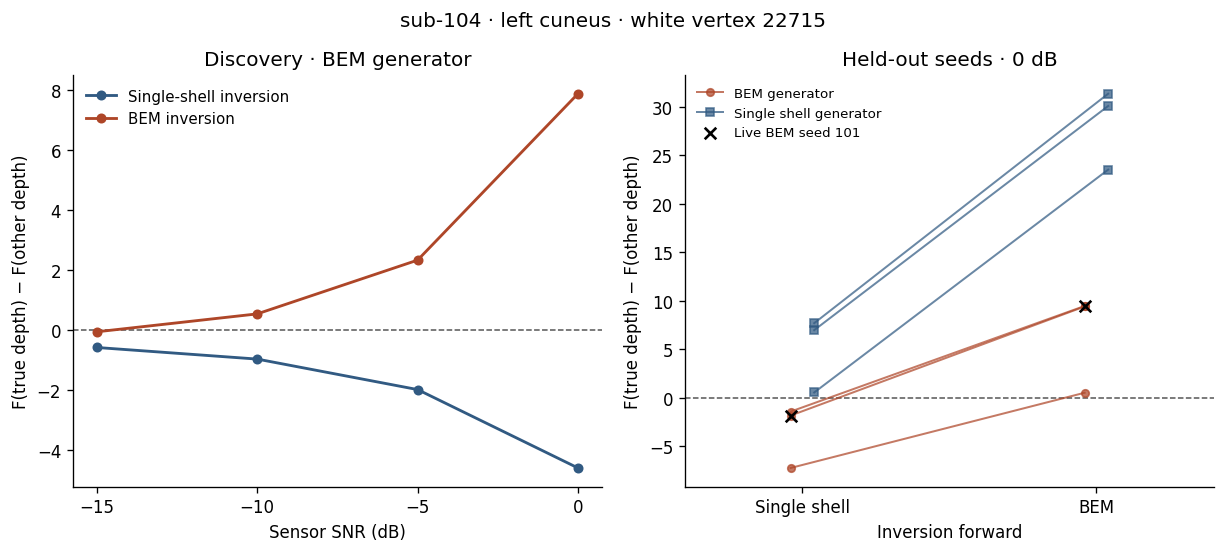

In [17]:
shell_color, bem_color = "#315a82", "#ae4628"
fig, (grid_ax, seed_ax) = plt.subplots(1, 2, figsize=(10.1, 4.5), constrained_layout=True)
grid = sorted((r for r in reference_rows if r[0] == "discovery"), key=lambda r: r[2])
for column, name, color in ((4, "Single-shell inversion", shell_color),
                            (5, "BEM inversion", bem_color)):
    grid_ax.plot([r[2] for r in grid], [r[column] for r in grid],
                 marker="o", ms=5, lw=1.7, color=color, label=name)
grid_ax.set(xlabel="Sensor SNR (dB)", xticks=snr_grid,
            ylabel="F(true depth) − F(other depth)", title="Discovery · BEM generator")
grid_ax.legend(frameon=False, loc="best", fontsize=9)

# Lines with the same color come from fresh seeds for the same generator.
# The two x positions on a line use identical sensor samples.
for generator, color, offset, marker in (("BEM", bem_color, -.04, "o"),
                                         ("Single shell", shell_color, .04, "s")):
    values = [r for r in reference_rows if r[0] != "discovery" and r[1] == generator]
    for i, row in enumerate(values):
        x = np.array([0., 1.]) + offset
        seed_ax.plot(x, row[-2:], color=color, marker=marker, alpha=.72,
                     lw=1.2, ms=4.5, label=generator + " generator" if i == 0 else None)
seed_ax.scatter(np.array([0., 1.]) - .04,
                [validation["shell_true_advantage"], validation["bem_true_advantage"]],
                marker="x", color="black", s=48, lw=1.6, label=f"Live BEM seed {validation_seed}",
                zorder=4)
seed_ax.set(xticks=(0, 1), xticklabels=("Single shell", "BEM"), xlim=(-.4, 1.4),
            xlabel="Inversion forward", ylabel="F(true depth) − F(other depth)",
            title=f"Held-out seeds · {selected_snr} dB")
seed_ax.legend(frameon=False, loc="best", fontsize=8)
for ax in (grid_ax, seed_ax):
    ax.axhline(0, color="0.32", lw=.9, ls="--", zorder=0)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
fig.suptitle(f"sub-104 · left cuneus · {true_layer} vertex {vertex_id}")
plt.show()

## What this example establishes

For the three held-out BEM recordings at 0 dB, BEM favored white while single
shell favored pial on 3/3 draws. Both solvers exceeded the three-unit margin
in opposite directions on 0/3. Both inversions favored the true white layer on all three reciprocal recordings.

The selected location is original bilateral downsampled vertex 22715 (left
cuneus) in this participant. Its BEM pial and white topographies are very
similar. For a noiseless BEM white dipole the fractions of squared sensor amplitude
explained are 1.0000 for the BEM white column and 0.9983 for the BEM pial
column. The corresponding single-shell values are 0.9857 for white and
0.9865 for pial. A small change in the topography is enough to change which
of two close competitors fits better.

The location was selected from one left occipital patch in one participant,
at a known source location with white Gaussian sensor noise. These trials
demonstrate a layer misclassification under a specified generating forward.
Estimating which forward is more accurate for measured MEG requires evidence
independent of either simulation model.

A separate depth control generated a **pial** source at the same vertex, 0 dB
and seed 101. Here the signed contrast for the true layer is **F(pial) − F(white)**.
Single shell gave +11.925 and selected pial.
BEM gave +6.955 and selected pial.
To reproduce this additional measurement, run the following before cleanup.

```python
pial_control = fit_realization("BEM", compact_vertex, "pial", 0, 101, work / "pial-control")
```


## Optional full replication

Set the switch below to regenerate all stored rows with the public
`model_comparison` function used for the live fits. Each row uses the same
anatomical vertex, the indicated generator, and its own recorded seed and
SNR. Only the two default live runs execute when the switch is false.

In [18]:
rerun_all = False
if rerun_all:
    for role, generator, snr, seed, reference_shell, reference_bem in reference_rows:
        run = fit_realization(generator, compact_vertex, true_layer, snr, seed,
                              work / f"replay-{role}-{generator}-{snr}-{seed}")
        # The tolerance is absolute in log-evidence units and allows for numerical
        # differences between SPM installations. It applies to both signed contrasts.
        np.testing.assert_allclose([run["shell_true_advantage"], run["bem_true_advantage"]],
                                   [reference_shell, reference_bem], rtol=0, atol=0.1)
    print(f"Reproduced {len(reference_rows)} paired fits.")

## References and cleanup

Nolte (2003) describes the single-shell approximation.
[Physics in Medicine & Biology](https://doi.org/10.1088/0031-9155/48/22/002).

Gramfort et al. (2013) describe MNE-Python.
[Frontiers in Neuroscience](https://doi.org/10.3389/fnins.2013.00267).

Bonaiuto et al. (2018) compare laminar inference methods using simulations.
[NeuroImage](https://doi.org/10.1016/j.neuroimage.2017.11.068).

Release SPM and remove the temporary working files. The reference results and
live evidence values remain available in the notebook.

In [19]:
spm.terminate()
workspace.cleanup()